In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# 1. Loading the Telco Customer Churn dataset
# Change 'churn.csv' if your filename is different!
df = pd.read_csv(r"C:\Users\Admin\Desktop\Telco-Customer-Churn.csv")

print("="*60)
print("DATA DIAGNOSTICS & CLEANING")
print("="*60)

# Checking data types before cleaning
print(f"Original data type of TotalCharges: {df['TotalCharges'].dtype}")

# Converting TotalCharges to numeric, turning hidden blank spaces into NaN (nulls)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Counting how many nulls were introduced by blank spaces
null_count = df['TotalCharges'].isnull().sum()
print(f"Number of blank/missing spaces found in TotalCharges: {null_count}")

# Droping rows with missing TotalCharges values since it's a very tiny amount
df = df.dropna(subset=['TotalCharges'])
print(f"Cleaned dataset shape: {df.shape}")

# Showing the target class distribution to look at the imbalance
print("\nTarget Class Distribution (Churn):")
print(df['Churn'].value_counts(normalize=True))

df.head()


DATA DIAGNOSTICS & CLEANING
Original data type of TotalCharges: str
Number of blank/missing spaces found in TotalCharges: 11
Cleaned dataset shape: (7032, 21)

Target Class Distribution (Churn):
Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# 2. Separate features (X) and target variable (y)

if 'customerID' in df.columns:
    X = df.drop(columns=['customerID', 'Churn'])
else:
    # If no customerID exists, just drop the target variable
    X = df.drop(columns=['Churn'])

# Converting target 'Yes'/'No' string labels into numeric 1 and 0 values
y = df['Churn'].map({'Yes': 1, 'No': 0})

# Identifying continuous and categorical columns automatically
numeric_cols = ['MonthlyCharges', 'TotalCharges']
categorical_cols = [col for col in X.columns if col not in numeric_cols]

# Build a preprocessing pipeline to encode and scale simultaneously
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ])

# 3. Transforming the feature matrix and perform an 80/20 train/test split
X_processed = preprocessor.fit_transform(X)

# Get the newly generated feature column names for our importance plots later
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
feature_names = numeric_cols + encoded_cat_cols

X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.20, random_state=42, stratify=y
)

# Calculating the perfect scale_pos_weight balance value to feed into XGBoost later
num_neg = np.sum(y_train == 0)
num_pos = np.sum(y_train == 1)
scale_weight_val = num_neg / num_pos

print("="*60)
print("DATA TRANSFORMATION SUMMARY")
print("="*60)
print(f"Training features matrix shape: {X_train.shape}")
print(f"Testing features matrix shape: {X_test.shape}")
print(f"Calculated negative-to-positive class balancing weight: {scale_weight_val:.2f}")


DATA TRANSFORMATION SUMMARY
Training features matrix shape: (5625, 100)
Testing features matrix shape: (1407, 100)
Calculated negative-to-positive class balancing weight: 2.76


In [4]:

try:
    from xgboost import XGBClassifier
except ModuleNotFoundError:
    print("XGBoost not found. Installing via pip...")
    import sys
    !{sys.executable} -m pip install xgboost
    from xgboost import XGBClassifier

print("="*60)
print("TRAINING MODELS WITH CLASS BALANCING")
print("="*60)

# 1. Initialize and train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1] # Extract probabilities for ROC-AUC
print("✔ Random Forest Model trained successfully!")

# 2. Initialize and train XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=scale_weight_val, # Addresses class imbalance directly
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1] # Extract probabilities for ROC-AUC
print("✔ XGBoost Model trained successfully!")

# Print Multi-Class/Binary Benchmark Performance Reports
print("\n" + "="*60)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, rf_preds))

print("="*60)
print("XGBOOST CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, xgb_preds))


TRAINING MODELS WITH CLASS BALANCING
✔ Random Forest Model trained successfully!
✔ XGBoost Model trained successfully!

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.86      0.81      0.84      1033
           1       0.55      0.65      0.60       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.77      1407

XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.87      0.74      0.80      1033
           1       0.50      0.71      0.58       374

    accuracy                           0.73      1407
   macro avg       0.69      0.72      0.69      1407
weighted avg       0.77      0.73      0.74      1407



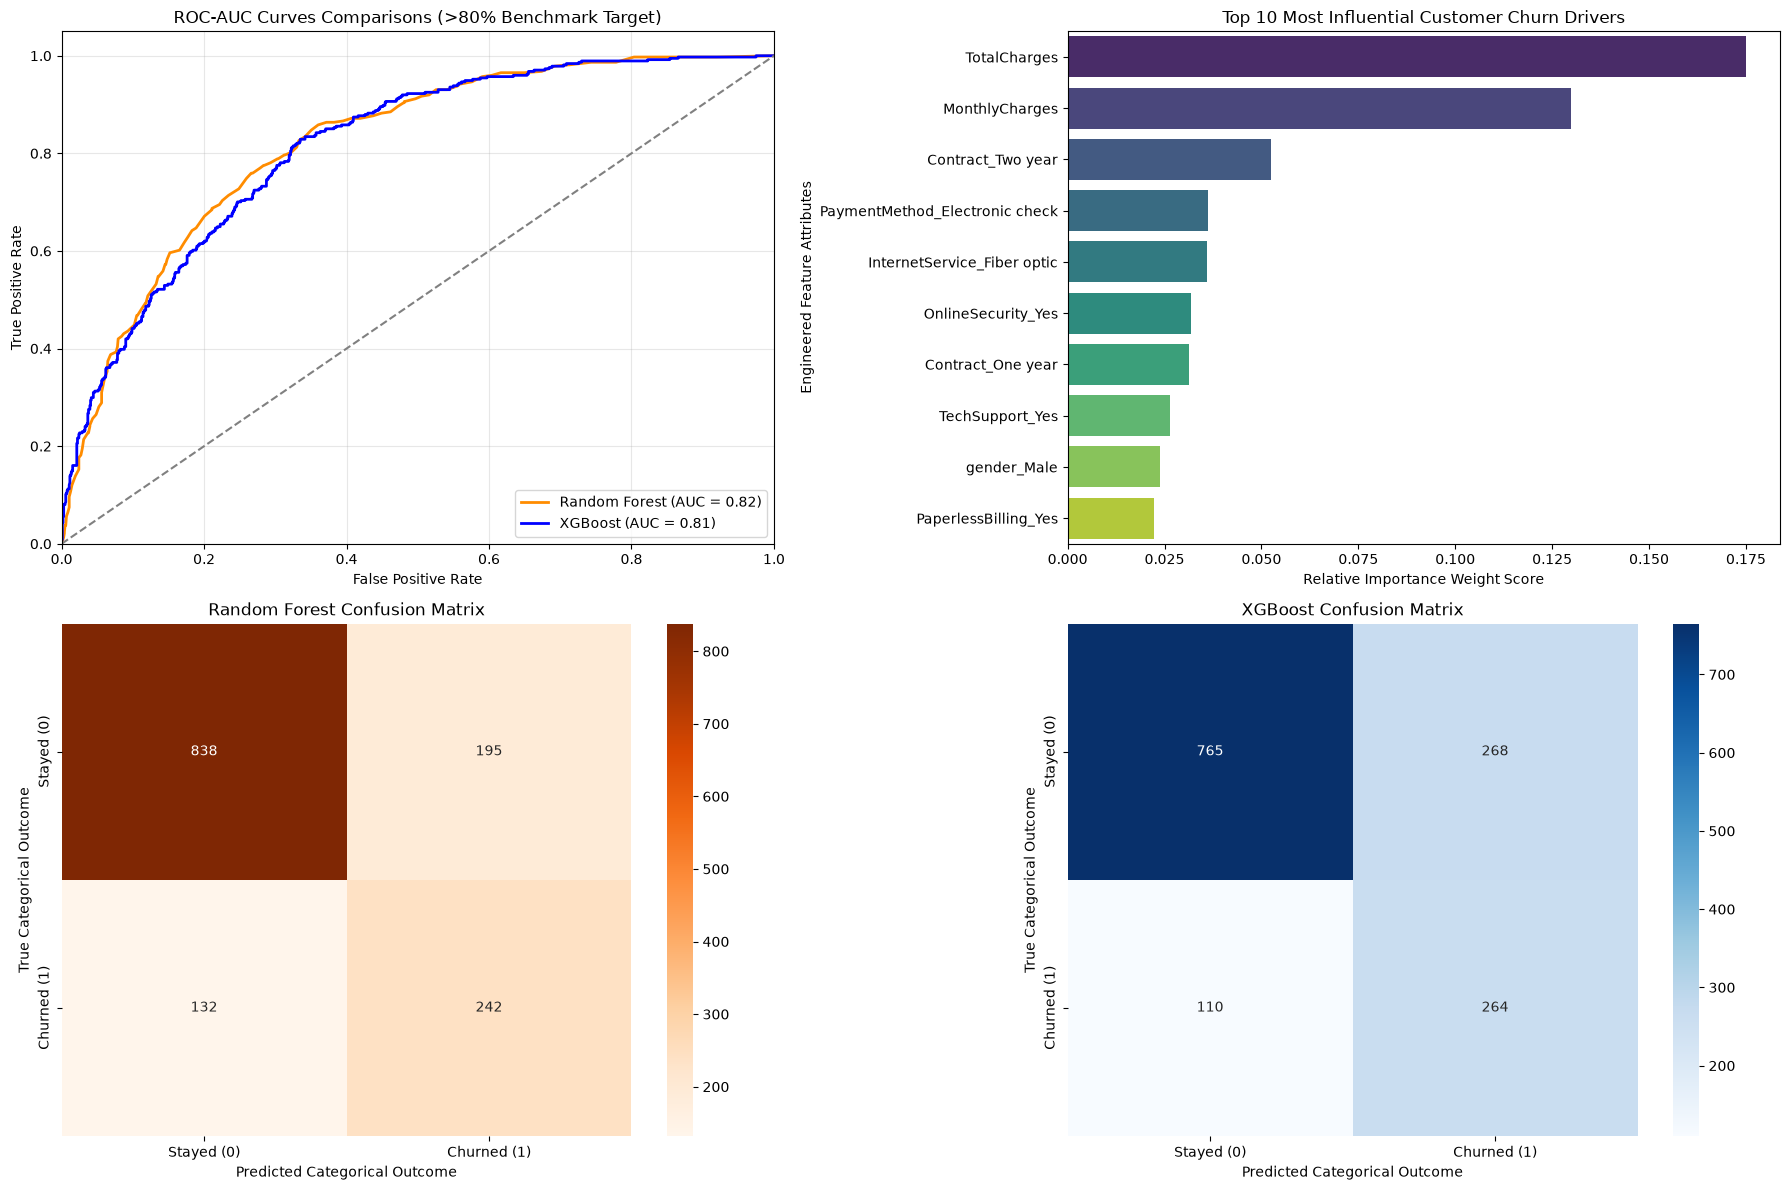

In [9]:

# 1. Computing ROC Curve and AUC scores for both models
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# 2. Extracting Top 10 Most Influential Feature Importances from Random Forest
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1][:10]  # Filter top 10 indices
top_10_features = [feature_names[i] for i in indices]
top_10_importances = importances[indices]

# Setting up a grid layout with 3 plots
fig = plt.figure(figsize=(18, 12))

# ----------------------------------------------------
# PLOT 1: ROC-AUC CURVE OVERLAYS
# ----------------------------------------------------
ax1 = plt.subplot(2, 2, 1)
ax1.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')
ax1.plot(fpr_xgb, tpr_xgb, color='blue', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC-AUC Curves Comparisons (>80% Benchmark Target)')
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)


# PLOT 2: TOP 10 FEATURE IMPORTANCE BAR CHART 
# ----------------------------------------------------
ax2 = plt.subplot(2, 2, 2)
# Assigning y to hue and adding legend=False keeps the colors beautiful and future-proof
sns.barplot(x=top_10_importances, y=top_10_features, hue=top_10_features, palette="viridis", legend=False, ax=ax2)
ax2.set_title('Top 10 Most Influential Customer Churn Drivers')
ax2.set_xlabel('Relative Importance Weight Score')
ax2.set_ylabel('Engineered Feature Attributes')


# ----------------------------------------------------
# PLOT 3: RANDOM FOREST CONFUSION MATRIX HEATMAP
# ----------------------------------------------------
ax3 = plt.subplot(2, 2, 3)
cm_rf = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges', ax=ax3,
            xticklabels=['Stayed (0)', 'Churned (1)'], yticklabels=['Stayed (0)', 'Churned (1)'])
ax3.set_title('Random Forest Confusion Matrix')
ax3.set_xlabel('Predicted Categorical Outcome')
ax3.set_ylabel('True Categorical Outcome')

# ----------------------------------------------------
# PLOT 4: XGBOOST CONFUSION MATRIX HEATMAP
# ----------------------------------------------------
ax4 = plt.subplot(2, 2, 4)
cm_xgb = confusion_matrix(y_test, xgb_preds)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=ax4,
            xticklabels=['Stayed (0)', 'Churned (1)'], yticklabels=['Stayed (0)', 'Churned (1)'])
ax4.set_title('XGBoost Confusion Matrix')
ax4.set_xlabel('Predicted Categorical Outcome')
ax4.set_ylabel('True Categorical Outcome')

plt.tight_layout()
plt.show()
